<a href="https://colab.research.google.com/github/iqbaal24/ML2026/blob/main/JS09_Klasifikasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS09 - Klasifikasi
Praktikum 1 (k-NN), Praktikum 2 (Naive Bayes data dummy), Praktikum 3 (Naive Bayes data multimoda), Tugas 1 (k-NN `voice.csv`), dan Tugas 2 (Multinomial Naive Bayes `spam.csv`).

**Cara pakai:** upload file `iris.csv`, `spam.csv`, dan `voice.csv` ke Colab (folder `/content`), lalu jalankan sel dari atas ke bawah. Jika file belum ada, akan muncul tombol upload otomatis.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

def cek_file(nama):
    """Pastikan file dataset ada. Kalau belum, minta upload (Colab)."""
    if not os.path.exists(nama):
        try:
            from google.colab import files
            print(f'{nama} belum ditemukan, silakan upload filenya:')
            files.upload()
        except ImportError:
            raise FileNotFoundError(f'{nama} tidak ditemukan. Letakkan di folder yang sama dengan notebook ini.')
    print(f'{nama} siap dipakai.')

---
# Praktikum 1 - k-Nearest Neighbors (kNN)
Dataset: `iris.csv`
## Langkah 1 - Load Data

In [2]:
cek_file('iris.csv')
data = pd.read_csv('iris.csv')
data.head()

iris.csv belum ditemukan, silakan upload filenya:


Saving iris.csv to iris.csv
iris.csv siap dipakai.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Langkah 2 - Eksplorasi Data

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [4]:
data.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [5]:
data['species'].value_counts()

,count
species,
setosa,50
versicolor,50
virginica,50


## Langkah 3 - Visualisasi Data

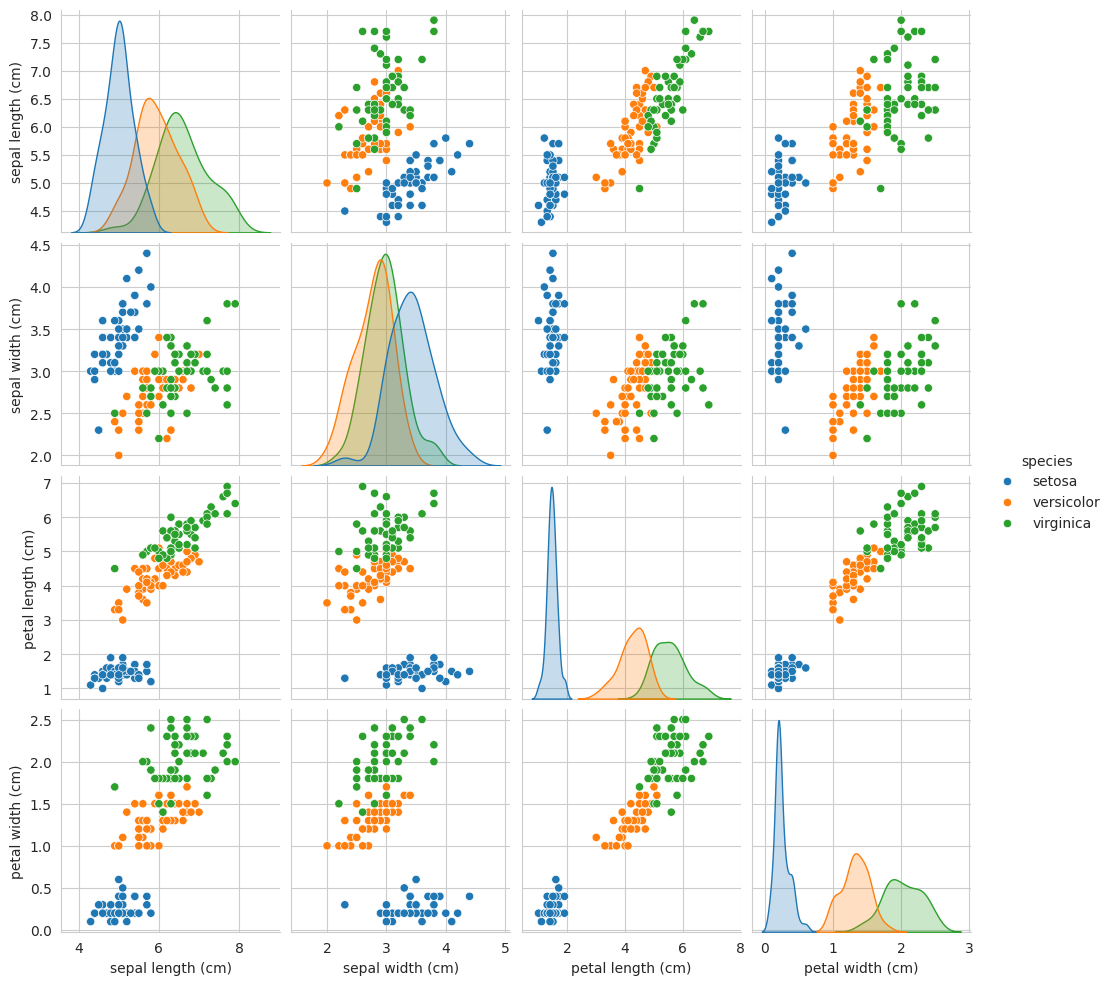

In [6]:
sns.pairplot(data, hue='species')
plt.show()

## Langkah 4 - Preprocessing
Pemisahan fitur dan label, split data (70% train, 30% test), lalu standardisasi.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Langkah 5 - Buat Model kNN

In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

## Langkah 6 - Evaluasi Model kNN

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



Mencari nilai K terbaik (K = 1 sampai 10) pada data test.

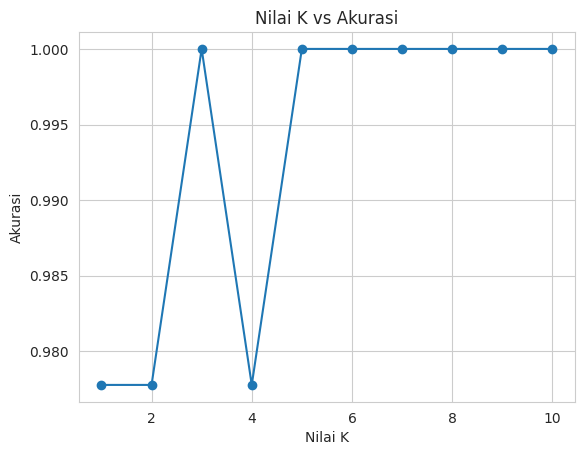

In [10]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()

Perbandingan akurasi data training dan data testing.

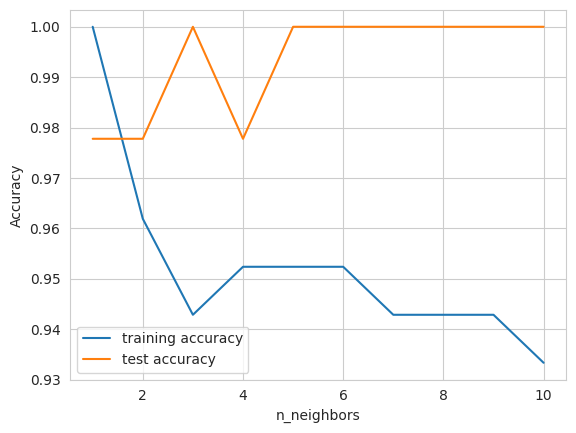

In [11]:
train_acc, test_acc = [], []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), train_acc, label='training accuracy')
plt.plot(range(1, 11), test_acc, label='test accuracy')
plt.ylabel('Accuracy')
plt.xlabel('n_neighbors')
plt.legend()
plt.show()

---
# Praktikum 2 - Klasifikasi Naive Bayes dengan Data Dummy
## Langkah 1 - Buat Dataset Dummy

In [12]:
from sklearn.datasets import make_classification

# Hasil make_classification: X (fitur, float) dan y (label, sudah berupa angka)
X, y = make_classification(n_samples=30, n_features=2, n_classes=2,
                           n_informative=2, n_redundant=0, n_repeated=0,
                           random_state=42)

# Multinomial NB butuh fitur diskrit (tidak negatif), jadi nilai diubah dulu
X = np.absolute(X)
X = np.round(X, 2) * 100
X = X.astype(int)

print(X)
print(y)

[[175 172]
 [ 53 106]
 [211 154]
 [124  66]
 [115  84]
 [ 50 142]
 [160  85]
 [ 16  73]
 [111 125]
 [ 80  85]
 [ 83  71]
 [179 210]
 [122  85]
 [ 53  66]
 [182 265]
 [ 93 109]
 [ 26  80]
 [ 46 113]
 [115 105]
 [150  85]
 [206 110]
 [250  83]
 [ 18 114]
 [112 139]
 [105  78]
 [122  70]
 [ 66  92]
 [ 20  70]
 [ 67  43]
 [ 36  54]]
[0 1 0 1 1 1 1 1 1 1 0 0 1 0 0 0 0 0 1 1 1 1 0 0 0 1 1 0 0 0]


## Langkah 2 (Opsional) - Membuat Data Frame

In [13]:
y_new = y.reshape(len(y), 1)
data_dummy = np.concatenate((X, y_new), axis=1)

nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']
df = pd.DataFrame(data_dummy, columns=nama_kolom)
df.head()

,Fitur 1,Fitur 2,Label
0,175,172,0
1,53,106,1
2,211,154,0
3,124,66,1
4,115,84,1


## Langkah 3 (Opsional) - Labeling

In [14]:
labels = {1: 'Kelas A', 0: 'Kelas B'}

df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)
df_label.head()

,Fitur 1,Fitur 2,Label
0,175,172,Kelas B
1,53,106,Kelas A
2,211,154,Kelas B
3,124,66,Kelas A
4,115,84,Kelas A


## Langkah 4 - Visualisasi Data

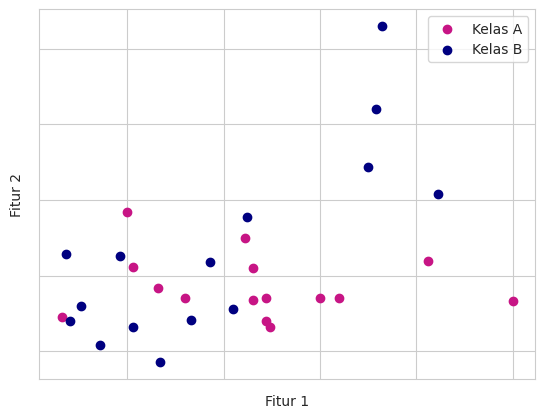

In [15]:
colors = {'Kelas A': 'MediumVioletRed', 'Kelas B': 'Navy'}

gb = df_label.groupby('Label')
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['Kelas A'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['Kelas B'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

## Langkah 5 - Model Multinomial Naive Bayes

In [16]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

mnb = MultinomialNB()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

mnb.fit(X_train, y_train)

y_train_pred = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.7142857142857143
Hasil akurasi data test: 0.5555555555555556


## Langkah 6 - Model Gaussian Naive Bayes

In [17]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_train_pred_gnb = gnb.predict(X_train)
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

y_test_pred_gnb = gnb.predict(X_test)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.7142857142857143
Hasil akurasi data test (Gaussian): 0.5555555555555556


---
# Praktikum 3 - Naive Bayes dengan Data Multimoda
Klasifikasi SMS spam/ham dengan Multinomial Naive Bayes. Dataset: `spam.csv`
## Langkah 1 - Load Data

In [18]:
cek_file('spam.csv')
df = pd.read_csv('spam.csv', encoding='latin-1')  # encoding latin-1 diperlukan karena ada karakter khusus
df.head()

spam.csv belum ditemukan, silakan upload filenya:


Saving spam.csv to spam.csv
spam.csv siap dipakai.


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## Langkah 2 - Preprocessing
### Langkah 2a - Drop Kolom

In [19]:
# Drop 3 kolom terakhir dengan fungsi iloc
df = df.drop(df.iloc[:, 2:], axis=1)

# Ubah nama kolom: v1 = label, v2 = teks sms
df.columns = ['Labels', 'SMS']
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Langkah 2b - Inspeksi Data

In [20]:
# Jumlah data per kelas
print(df['Labels'].value_counts())
print('\n')

# Kelengkapan data
print(df.info())
print('\n')

# Statistik deskriptif
print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


### Langkah 2c - Encoding Label

In [21]:
new_labels = {'spam': 1, 'ham': 0}
df['Labels'] = df['Labels'].map(new_labels)
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


### Langkah 2d - Pisahkan Fitur dengan Label

In [22]:
X = df['SMS'].values
y = df['Labels'].values

## Langkah 3 - Ekstraksi Fitur (Bag of Words)
Split dilakukan lebih dulu agar tidak terjadi *leaking information*.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

bow = CountVectorizer()
X_train = bow.fit_transform(X_train)
X_test = bow.transform(X_test)   # hanya transform, tidak fit ulang

In [24]:
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7735
Dimensi data: (4457, 7735)


## Langkah 4 - Training dan Evaluasi Model

In [25]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

mnb = MultinomialNB()
mnb.fit(X_train, y_train)

y_pred_train = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_pred_train)

y_pred_test = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_pred_test)

print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9943908458604442
Hasil akurasi data test: 0.9838565022421525


---
# Tugas 1 - Klasifikasi Jenis Suara dengan kNN
Dataset: `voice.csv` (label `male` dan `female`)

Yang dikerjakan:
1. Membuat model kNN untuk mengklasifikasikan suara `male` dan `female`.
2. Eksperimen untuk mencari fitur paling optimal.
3. Mencari nilai k terbaik berdasarkan fitur terpilih, lengkap dengan grafik.

**Catatan metode:** pemilihan fitur dan nilai k dilakukan dengan *cross-validation* pada **data training saja**. Data test hanya dipakai untuk pelaporan akhir, supaya hasilnya tidak bocor (*data leakage*).
## 1. Load dan Eksplorasi Data

In [26]:
cek_file('voice.csv')
voice = pd.read_csv('voice.csv')
voice.head()

voice.csv belum ditemukan, silakan upload filenya:


Saving voice.csv to voice.csv
voice.csv siap dipakai.


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [27]:
print(voice.shape)
print(voice['label'].value_counts())
print('\nMissing value per kolom:', voice.isnull().sum().sum())
voice.describe().T

(3168, 21)
label
male      1584
female    1584
Name: count, dtype: int64

Missing value per kolom: 0


,count,mean,std,min,25%,50%,75%,max
meanfreq,3168.0,0.180907,0.029918,0.039363,0.163662,0.184838,0.199146,0.251124
sd,3168.0,0.057126,0.016652,0.018363,0.041954,0.059155,0.067020,0.115273
median,3168.0,0.185621,0.036360,0.010975,0.169593,0.190032,0.210618,0.261224
Q25,3168.0,0.140456,0.048680,0.000229,0.111087,0.140286,0.175939,0.247347
Q75,3168.0,0.224765,0.023639,0.042946,0.208747,0.225684,0.243660,0.273469
IQR,3168.0,0.084309,0.042783,0.014558,0.042560,0.094280,0.114175,0.252225
skew,3168.0,3.140168,4.240529,0.141735,1.649569,2.197101,2.931694,34.725453
kurt,3168.0,36.568461,134.928661,2.068455,5.669547,8.318463,13.648905,1309.612887
sp.ent,3168.0,0.895127,0.044980,0.738651,0.861811,0.901767,0.928713,0.981997
sfm,3168.0,0.408216,0.177521,0.036876,0.258041,0.396335,0.533676,0.842936


## 2. Preprocessing dan Split Data
Label di-encode (male = 1, female = 0). Data dibagi 80% train dan 20% test dengan `stratify` agar proporsi kelas sama.

In [28]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

X_all = voice.drop(columns='label')
y_all = (voice['label'] == 'male').astype(int)
semua_fitur = list(X_all.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Jumlah fitur:', len(semua_fitur))
print('Data train:', X_train.shape, '| Data test:', X_test.shape)

Jumlah fitur: 20
Data train: (2534, 20) | Data test: (634, 20)


## 3. Model Awal (Semua Fitur, k = 5)
Fitur di-standardisasi di dalam `pipeline` supaya `scaler` hanya belajar dari data training pada setiap lipatan CV.

In [29]:
def buat_model(k=5):
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

def cv_acc(fitur, k=5):
    return cross_val_score(buat_model(k), X_train[fitur], y_train, cv=cv, scoring='accuracy').mean()

def test_acc(fitur, k=5):
    m = buat_model(k).fit(X_train[fitur], y_train)
    return m.score(X_test[fitur], y_test)

print(f'Semua fitur ({len(semua_fitur)}) | CV acc: {cv_acc(semua_fitur):.4f} | Test acc: {test_acc(semua_fitur):.4f}')

Semua fitur (20) | CV acc: 0.9696 | Test acc: 0.9763


## 4. Eksperimen Pemilihan Fitur
Lima pendekatan dibandingkan:
- **A.** Semua fitur (pembanding)
- **B.** Peringkat korelasi fitur dengan label
- **C.** Peringkat skor ANOVA F (`SelectKBest`)
- **D.** Forward Selection (`SequentialFeatureSelector`)
- **E.** Buang fitur yang saling berkorelasi tinggi (> 0.90)

### B. Peringkat Korelasi dengan Label

meanfun     0.832
IQR         0.618
Q25         0.510
sp.ent      0.489
sd          0.478
sfm         0.359
centroid    0.337
meanfreq    0.337
median      0.282
mindom      0.195
maxdom      0.192
dfrange     0.188
meandom     0.185
mode        0.171
maxfun      0.164
minfun      0.136
kurt        0.087
Q75         0.067
skew        0.039
modindx     0.029
dtype: float64


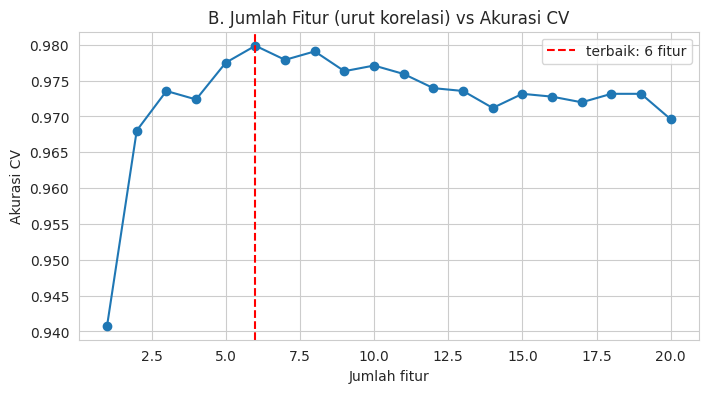

Fitur terpilih B: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm']


In [30]:
korelasi = X_train.corrwith(y_train).abs().sort_values(ascending=False)
urut_korelasi = list(korelasi.index)
print(korelasi.round(3))

acc_b = [cv_acc(urut_korelasi[:n]) for n in range(1, len(semua_fitur) + 1)]
n_b = int(np.argmax(acc_b)) + 1
fitur_b = urut_korelasi[:n_b]

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(acc_b) + 1), acc_b, marker='o')
plt.axvline(n_b, color='red', linestyle='--', label=f'terbaik: {n_b} fitur')
plt.title('B. Jumlah Fitur (urut korelasi) vs Akurasi CV')
plt.xlabel('Jumlah fitur')
plt.ylabel('Akurasi CV')
plt.legend()
plt.show()
print('Fitur terpilih B:', fitur_b)

### C. Peringkat Skor ANOVA F (SelectKBest)

meanfun     5697.9
IQR         1566.5
Q25          890.4
sp.ent       794.1
sd           750.8
sfm          375.2
centroid     324.4
meanfreq     324.4
median       218.3
mindom       100.4
maxdom        96.5
dfrange       93.0
meandom       89.2
mode          76.1
maxfun        69.7
minfun        47.4
kurt          19.3
Q75           11.3
skew           3.8
modindx        2.1
dtype: float64


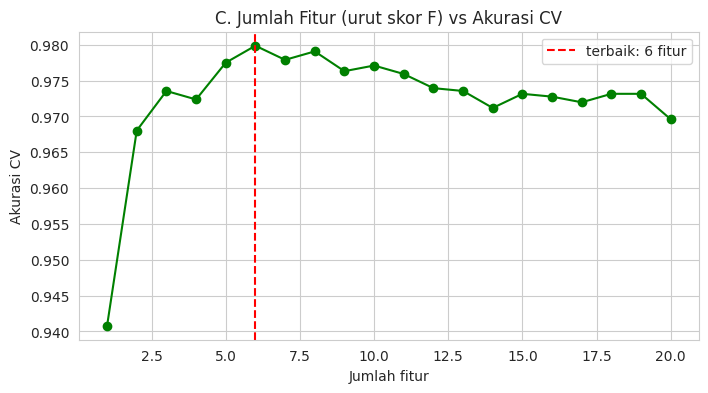

Fitur terpilih C: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm']


In [31]:
from sklearn.feature_selection import SelectKBest, f_classif

skor = SelectKBest(f_classif, k='all').fit(X_train, y_train)
skor_f = pd.Series(skor.scores_, index=semua_fitur).sort_values(ascending=False)
urut_f = list(skor_f.index)
print(skor_f.round(1))

acc_c = [cv_acc(urut_f[:n]) for n in range(1, len(semua_fitur) + 1)]
n_c = int(np.argmax(acc_c)) + 1
fitur_c = urut_f[:n_c]

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(acc_c) + 1), acc_c, marker='o', color='green')
plt.axvline(n_c, color='red', linestyle='--', label=f'terbaik: {n_c} fitur')
plt.title('C. Jumlah Fitur (urut skor F) vs Akurasi CV')
plt.xlabel('Jumlah fitur')
plt.ylabel('Akurasi CV')
plt.legend()
plt.show()
print('Fitur terpilih C:', fitur_c)

### D. Forward Selection

In [32]:
from sklearn.feature_selection import SequentialFeatureSelector

sfs = SequentialFeatureSelector(buat_model(5), n_features_to_select='auto', tol=0.001,
                                direction='forward', scoring='accuracy', cv=cv, n_jobs=-1)
sfs.fit(X_train, y_train)
fitur_d = list(X_train.columns[sfs.get_support()])
print('Fitur terpilih D:', fitur_d)

Fitur terpilih D: ['IQR', 'sfm', 'mode', 'meanfun']


### E. Buang Fitur yang Saling Berkorelasi Tinggi

In [33]:
korelasi_antar = X_train.corr().abs()
atas = korelasi_antar.where(np.triu(np.ones(korelasi_antar.shape), k=1).astype(bool))
buang = [c for c in atas.columns if (atas[c] > 0.90).any()]
fitur_e = [f for f in semua_fitur if f not in buang]
print('Fitur dibuang:', buang)
print('Fitur tersisa E:', fitur_e)

Fitur dibuang: ['median', 'Q25', 'kurt', 'centroid', 'dfrange']
Fitur tersisa E: ['meanfreq', 'sd', 'Q75', 'IQR', 'skew', 'sp.ent', 'sfm', 'mode', 'meanfun', 'minfun', 'maxfun', 'meandom', 'mindom', 'maxdom', 'modindx']


### Perbandingan Semua Skenario Fitur

,Skenario,Jumlah Fitur,Akurasi CV (train),Akurasi Test
0,D. Forward Selection,4,0.9807,0.9890
1,C. SelectKBest (ANOVA F),6,0.9799,0.9858
2,B. Korelasi,6,0.9799,0.9858
3,A. Semua fitur,20,0.9696,0.9763
4,E. Buang korelasi tinggi,15,0.9696,0.9779


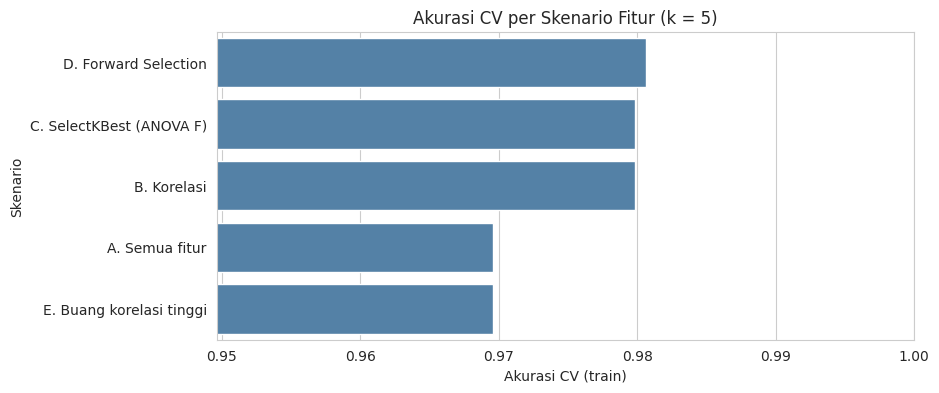

Skenario terbaik (berdasarkan akurasi CV): D. Forward Selection
Jumlah fitur: 4
Fitur yang dipakai: ['IQR', 'sfm', 'mode', 'meanfun']


In [34]:
skenario = {
    'A. Semua fitur': semua_fitur,
    'B. Korelasi': fitur_b,
    'C. SelectKBest (ANOVA F)': fitur_c,
    'D. Forward Selection': fitur_d,
    'E. Buang korelasi tinggi': fitur_e,
}

hasil = pd.DataFrame({
    'Skenario': list(skenario.keys()),
    'Jumlah Fitur': [len(f) for f in skenario.values()],
    'Akurasi CV (train)': [cv_acc(f) for f in skenario.values()],
    'Akurasi Test': [test_acc(f) for f in skenario.values()],
}).sort_values('Akurasi CV (train)', ascending=False).reset_index(drop=True)

display(hasil.round(4))

plt.figure(figsize=(9, 4))
sns.barplot(data=hasil, y='Skenario', x='Akurasi CV (train)', color='steelblue')
plt.xlim(hasil['Akurasi CV (train)'].min() - 0.02, 1.0)
plt.title('Akurasi CV per Skenario Fitur (k = 5)')
plt.show()

nama_terbaik = hasil.loc[0, 'Skenario']
fitur_terbaik = skenario[nama_terbaik]
print('Skenario terbaik (berdasarkan akurasi CV):', nama_terbaik)
print(f'Jumlah fitur: {len(fitur_terbaik)}')
print('Fitur yang dipakai:', fitur_terbaik)

## 5. Mencari Nilai k Terbaik
Pada fitur terpilih, k = 1 sampai 30 dievaluasi dengan CV. Grafik train vs test ditampilkan sebagai pembanding.

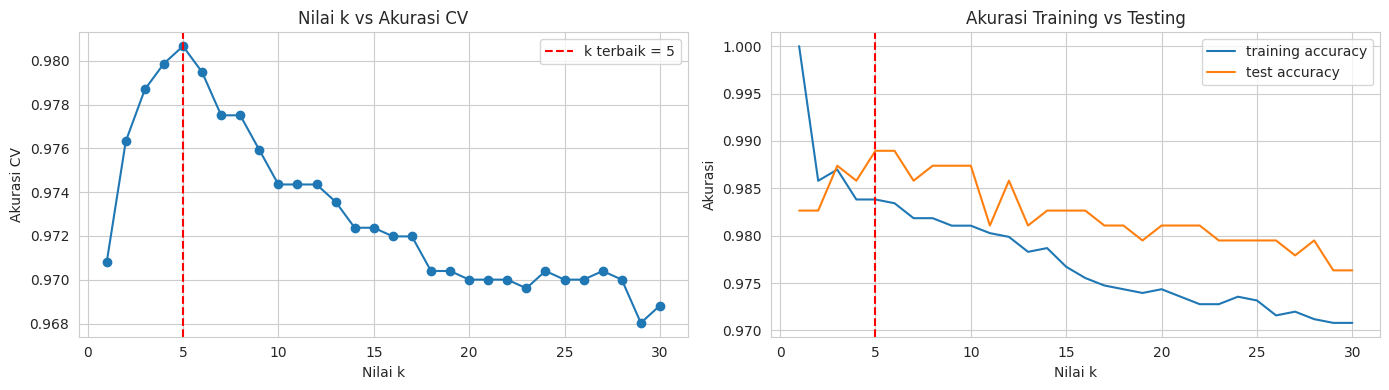

k terbaik (akurasi CV tertinggi): 5 -> 0.9807


In [35]:
rentang_k = range(1, 31)
cv_k, train_k, test_k = [], [], []

for k in rentang_k:
    cv_k.append(cv_acc(fitur_terbaik, k))
    m = buat_model(k).fit(X_train[fitur_terbaik], y_train)
    train_k.append(m.score(X_train[fitur_terbaik], y_train))
    test_k.append(m.score(X_test[fitur_terbaik], y_test))

k_terbaik = list(rentang_k)[int(np.argmax(cv_k))]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(rentang_k, cv_k, marker='o')
ax[0].axvline(k_terbaik, color='red', linestyle='--', label=f'k terbaik = {k_terbaik}')
ax[0].set_title('Nilai k vs Akurasi CV')
ax[0].set_xlabel('Nilai k')
ax[0].set_ylabel('Akurasi CV')
ax[0].legend()

ax[1].plot(rentang_k, train_k, label='training accuracy')
ax[1].plot(rentang_k, test_k, label='test accuracy')
ax[1].axvline(k_terbaik, color='red', linestyle='--')
ax[1].set_title('Akurasi Training vs Testing')
ax[1].set_xlabel('Nilai k')
ax[1].set_ylabel('Akurasi')
ax[1].legend()
plt.tight_layout()
plt.show()

print(f'k terbaik (akurasi CV tertinggi): {k_terbaik} -> {max(cv_k):.4f}')

## 6. Evaluasi Model Akhir

Akurasi data test: 0.989

Laporan Klasifikasi:
               precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



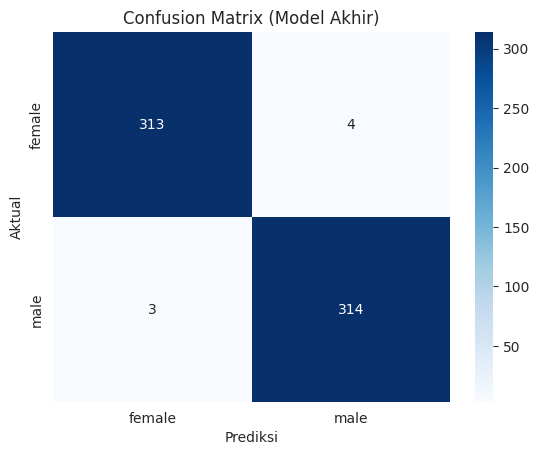

In [36]:
model_akhir = buat_model(k_terbaik).fit(X_train[fitur_terbaik], y_train)
y_pred = model_akhir.predict(X_test[fitur_terbaik])

print('Akurasi data test:', round(accuracy_score(y_test, y_pred), 4))
print('\nLaporan Klasifikasi:\n', classification_report(y_test, y_pred, target_names=['female', 'male']))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['female', 'male'], yticklabels=['female', 'male'])
plt.title('Confusion Matrix (Model Akhir)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

## Ringkasan Jawaban Tugas 1

In [37]:
print('Soal 1 - Model kNN dibuat dengan pipeline StandardScaler + KNeighborsClassifier.')
print(f'Soal 2 - Skenario fitur terbaik: {nama_terbaik} ({len(fitur_terbaik)} fitur)')
print('         Fitur:', ', '.join(fitur_terbaik))
print(f'Soal 3 - Nilai k terbaik: {k_terbaik} (akurasi CV {max(cv_k):.4f}, akurasi test {test_acc(fitur_terbaik, k_terbaik):.4f})')

Soal 1 - Model kNN dibuat dengan pipeline StandardScaler + KNeighborsClassifier.
Soal 2 - Skenario fitur terbaik: D. Forward Selection (4 fitur)
         Fitur: IQR, sfm, mode, meanfun
Soal 3 - Nilai k terbaik: 5 (akurasi CV 0.9807, akurasi test 0.9890)


---
# Tugas 2 - Multinomial Naive Bayes pada `spam.csv`
1. Multinomial Naive Bayes + `CountVectorizer` dengan `stop_words` aktif, lalu evaluasi.
2. Multinomial Naive Bayes + `TF-IDF` dengan `stop_words` aktif, evaluasi, bandingkan dengan nomor 1, lalu beri kesimpulan fitur terbaik.
## Persiapan Data

In [38]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

cek_file('spam.csv')
sms = pd.read_csv('spam.csv', encoding='latin-1')
sms = sms.iloc[:, :2]
sms.columns = ['Labels', 'SMS']
sms['Labels'] = sms['Labels'].map({'spam': 1, 'ham': 0})

Xs = sms['SMS'].values
ys = sms['Labels'].values

# Split yang sama dipakai untuk semua model agar perbandingannya adil
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    Xs, ys, test_size=0.2, random_state=42, stratify=ys)
print('Data train:', len(Xs_train), '| Data test:', len(Xs_test))

spam.csv siap dipakai.
Data train: 4457 | Data test: 1115


In [39]:
hasil_tugas2 = []

def evaluasi(nama, vektorizer):
    X_tr = vektorizer.fit_transform(Xs_train)   # fit hanya di data train
    X_te = vektorizer.transform(Xs_test)

    model = MultinomialNB().fit(X_tr, ys_train)
    pred_tr = model.predict(X_tr)
    pred = model.predict(X_te)

    print('=' * 60)
    print(nama)
    print('=' * 60)
    print(f'Jumlah fitur (kata): {X_tr.shape[1]}')
    print(f'Akurasi train: {accuracy_score(ys_train, pred_tr):.4f}')
    print(f'Akurasi test : {accuracy_score(ys_test, pred):.4f}')
    print('\nConfusion Matrix:\n', confusion_matrix(ys_test, pred))
    print('\nLaporan Klasifikasi:\n', classification_report(ys_test, pred, target_names=['ham', 'spam']))

    sns.heatmap(confusion_matrix(ys_test, pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
    plt.title(f'Confusion Matrix - {nama}')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.show()

    hasil_tugas2.append({
        'Model': nama,
        'Jumlah Fitur': X_tr.shape[1],
        'Akurasi Train': accuracy_score(ys_train, pred_tr),
        'Akurasi Test': accuracy_score(ys_test, pred),
        'Precision (spam)': precision_score(ys_test, pred),
        'Recall (spam)': recall_score(ys_test, pred),
        'F1 (spam)': f1_score(ys_test, pred),
    })

## Soal 1 - CountVectorizer + stop_words

CountVectorizer + stop_words
Jumlah fitur (kata): 7440
Akurasi train: 0.9946
Akurasi test : 0.9839

Confusion Matrix:
 [[960   6]
 [ 12 137]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



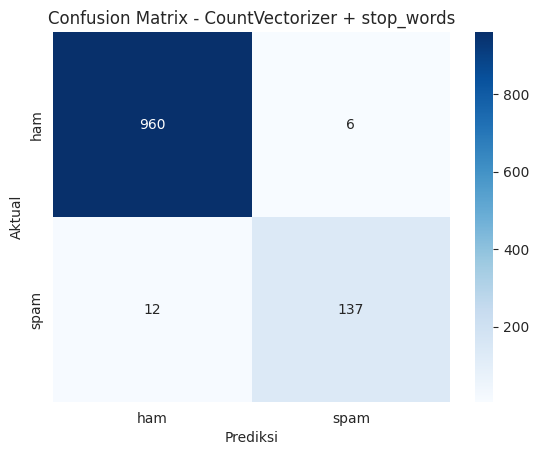

In [40]:
evaluasi('CountVectorizer + stop_words', CountVectorizer(stop_words='english'))

## Soal 2 - TF-IDF + stop_words

TF-IDF + stop_words
Jumlah fitur (kata): 7440
Akurasi train: 0.9845
Akurasi test : 0.9686

Confusion Matrix:
 [[966   0]
 [ 35 114]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



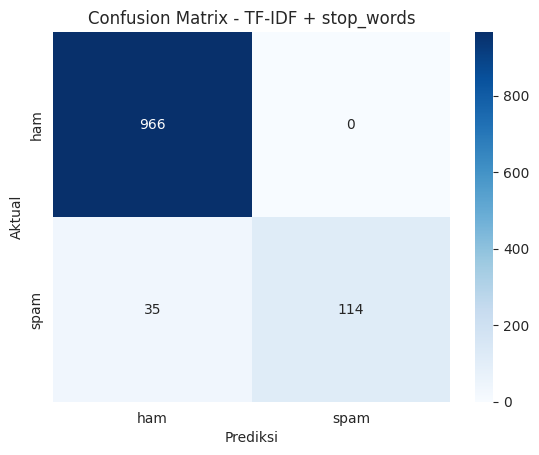

In [41]:
evaluasi('TF-IDF + stop_words', TfidfVectorizer(stop_words='english'))

## Pembanding Tambahan - Tanpa stop_words (seperti Praktikum 3)

CountVectorizer (tanpa stop_words)
Jumlah fitur (kata): 7701
Akurasi train: 0.9939
Akurasi test : 0.9839

Confusion Matrix:
 [[961   5]
 [ 13 136]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.91      0.94       149

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



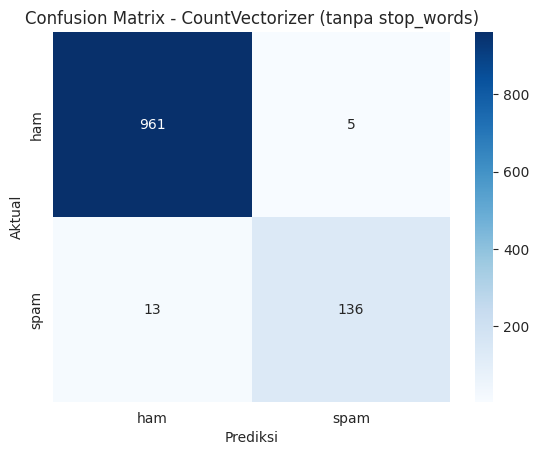

In [42]:
evaluasi('CountVectorizer (tanpa stop_words)', CountVectorizer())

## Perbandingan dan Kesimpulan

,Model,Jumlah Fitur,Akurasi Train,Akurasi Test,Precision (spam),Recall (spam),F1 (spam)
0,CountVectorizer + stop_words,7440,0.9946,0.9839,0.9580,0.9195,0.9384
1,TF-IDF + stop_words,7440,0.9845,0.9686,1.0000,0.7651,0.8669
2,CountVectorizer (tanpa stop_words),7701,0.9939,0.9839,0.9645,0.9128,0.9379


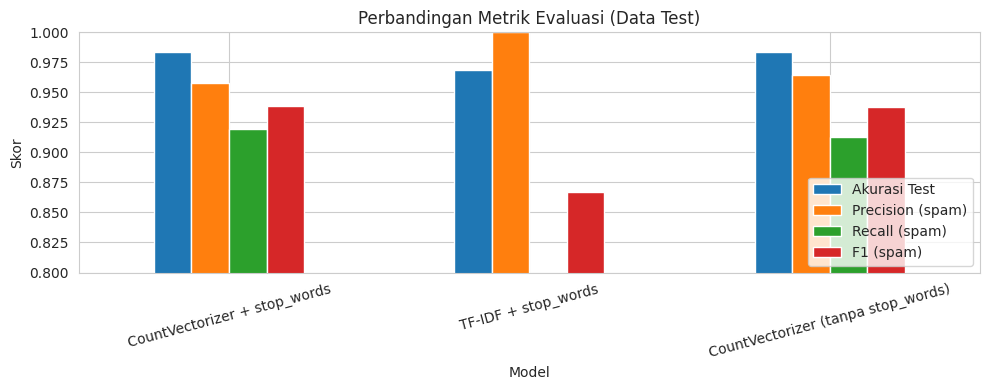

Fitur terbaik pada data spam.csv: CountVectorizer + stop_words
Akurasi test = 0.9839 | F1 (spam) = 0.9384 | Recall (spam) = 0.9195


In [43]:
tabel = pd.DataFrame(hasil_tugas2)
display(tabel.round(4))

tabel.set_index('Model')[['Akurasi Test', 'Precision (spam)', 'Recall (spam)', 'F1 (spam)']].plot(
    kind='bar', figsize=(10, 4), rot=15)
plt.title('Perbandingan Metrik Evaluasi (Data Test)')
plt.ylim(0.8, 1.0)
plt.ylabel('Skor')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Bandingkan hanya dua model yang diminta soal (pakai stop_words)
dua = tabel[tabel['Model'].str.contains('stop_words') & ~tabel['Model'].str.contains('tanpa')]
terbaik = dua.sort_values(['F1 (spam)', 'Akurasi Test'], ascending=False).iloc[0]
print(f"Fitur terbaik pada data spam.csv: {terbaik['Model']}")
print(f"Akurasi test = {terbaik['Akurasi Test']:.4f} | F1 (spam) = {terbaik['F1 (spam)']:.4f} | Recall (spam) = {terbaik['Recall (spam)']:.4f}")